# 네팔 건물 피해등급 — 모델 비교 v2 (test_5 수정본)

`test_5.ipynb`를 검토한 뒤 문제를 고친 복사본입니다. 원본은 그대로 둡니다.

| 문제 (test_5) | 수정 (v2) |
|---|---|
| 원본 CSV를 seed 20261016으로 직접 분할 → 팀 `final_holdout`의 80.0%가 학습에 섞임 | `preprocess.load_development()`와 저장된 5-fold만 사용, 홀드아웃은 읽지 않음 |
| 전체 데이터(홀드아웃 포함)로 지역·자재 표 작성 (셀 16) | 삭제. EDA는 development만 사용 |
| val로 후보를 고른 뒤 그 val이 들어간 3-fold CV로 다시 선택 | 모든 후보를 처음부터 같은 5-fold로 비교 |
| 기준선(val)·선택 모델(CV)·test 점수를 한 표에서 비교 | 모든 비교를 같은 fold의 OOF/fold 점수로 하고, fold별 짝지은 차이도 보고 |
| RandomForest가 geo ID 약 13,000개를 원-핫으로 받음 → Macro F1 0.36 | RF에는 geo ID를 숫자로 입력 |
| 처음 보는 범주를 그대로 `pd.Categorical`에 넣어 Pandas4Warning 발생 | 먼저 NaN으로 바꾼 뒤 범주형으로 변환 |
| 사용자 확정 전에 최종 test를 실행 | **최종 홀드아웃 평가는 실행하지 않음.** 후보와 평가 계획만 저장 |

주지표: labels=[1,2,3] Macro F1. 결과는 `outputs/test_5_v2/`(gitignore 대상)에 저장합니다.

### `C:\t_project_1_1`의 이전 실험에서 가져온 것

| 출처 | 내용 | v2 반영 |
|---|---|---|
| `nepal_interaction_sampling_experiments.py` | 결합변수 5개(geo1×진흙석재, 기초×진흙석재, 지붕×RC공학, 1층바닥×시멘트벽돌, 상부층×진흙석재) | `LGBM_joint5`로 팀 5-fold에서 다시 평가 |
| 같은 스크립트 | under_partial + class_weight balanced | `LGBM_under_partial_balanced`로 추가 |
| 같은 스크립트 | 대·중·소 통합지역 `region_combined` | 추가 안 함. geo_level_3가 상위 지역을 하나씩만 가져서(2절 계층 확인) 정보가 같음. 이전 실험에서도 점수가 소수점까지 같았음 |
| `modeling.ipynb` | 누수 없는 구조 파생변수(보조용도 수, 콘크리트/진흙 재료 수, 바닥·기초·지표면 조합 등) | `LGBM_struct`로 추가 |
| `modeling.ipynb` | `secondary_use_*_grade2/3` (정답 `damage_grade`로 만든 변수), 전체 데이터 기준 지역별 비율 | **채택 안 함. 정답 누수**라서 이 노트북의 Macro F1 0.72는 유효하지 않음 |

이전 실험들은 seed 42로 분할했지만 `building_id` 정렬 없이 나눠서, 팀 홀드아웃과 다른 분할이었습니다. 그래서 수치는 참고만 하고, 모두 팀 fold에서 다시 평가합니다.

In [ ]:
from pathlib import Path
import sys
import json
import time
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.stats import chi2_contingency, spearmanr

from sklearn.model_selection import ParameterGrid, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

from lightgbm import LGBMClassifier
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


# --------------------------------------------------
# 경로: 저장소 루트의 preprocess.py와 data/를 사용
# --------------------------------------------------
REPO = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "preprocess.py").exists()
)
sys.path.insert(0, str(REPO))

import preprocess as pp

# 모델 random_state. 데이터 분할 seed는 팀 계약(42)으로 고정돼 있어 여기서 정하지 않음
SEED = 20261016

DATA_DIR = REPO / "data"
OUT = REPO / "outputs" / "test_5_v2"
OUT.mkdir(parents=True, exist_ok=True)

GEO = pp.GEO
NUM = pp.NUMERIC
LABELS = [1, 2, 3]

if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"

plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)


def save_table(table, name):
    table.to_csv(
        OUT / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )


def save_json(value, name):
    text = json.dumps(
        value,
        ensure_ascii=False,
        indent=2,
        default=str
    )

    (OUT / name).write_text(text, encoding="utf-8")


print("저장소:", REPO)
print("결과 저장 폴더:", OUT)

저장소: C:\Users\jhj31\project_1\earthquake
결과 저장 폴더: C:\Users\jhj31\project_1\earthquake\outputs\test_5_v2


## 1. 팀 development 데이터와 고정 5-fold 불러오기

`load_development()`는 홀드아웃을 읽지 않습니다. 파일 해시가 `configs/data_contract.json`과 같은지 먼저 확인합니다.

In [2]:
contract = json.loads(
    (REPO / "configs" / "data_contract.json").read_text(encoding="utf-8")
)

file_hashes = {}

for name, expected in contract["files"].items():
    actual = pp.sha256_file(DATA_DIR / name)
    file_hashes[name] = actual
    assert actual == expected, f"{name} 해시가 데이터 계약과 다릅니다."

X, y, ids, cv = pp.load_development(DATA_DIR)

y = y.astype(int).rename("damage_grade")
folds = list(cv.split())

assert len(X) == contract["expected_rows"]
assert X.shape[1] == 38
assert len(folds) == contract["n_folds"] == 5
assert ids.is_unique

# 5개 validation fold가 development 전체를 정확히 한 번씩 덮는지 확인
covered = np.sort(np.concatenate([va for _, va in folds]))
assert np.array_equal(covered, np.arange(len(X)))

# EDA용 표 (development만)
dev = X.assign(damage_grade=y.to_numpy())

print("development 크기:", X.shape)

fold_counts = pd.crosstab(
    pd.Series(cv.test_fold, name="fold"),
    pd.Series(y.to_numpy(), name="damage_grade")
)

display(fold_counts)

package_names = [
    "pandas",
    "numpy",
    "scipy",
    "scikit-learn",
    "lightgbm",
    "imbalanced-learn"
]

versions = {
    name: importlib.metadata.version(name)
    for name in package_names
}

environment = {
    "python": platform.python_version(),
    "packages": versions,
    "preprocessing_version": contract["preprocessing_version"],
    "source_sha256": contract["source_sha256"],
    "data_files_sha256": file_hashes,
    "split_seed": contract["seed"],
    "model_seed": SEED
}

save_json(environment, "environment.json")
display(pd.Series(versions, name="버전"))

development 크기: (208480, 38)


damage_grade,1,2,3
fold,,,
0,4019,23722,13955
1,4020,23722,13954
2,4020,23721,13955
3,4020,23721,13955
4,4020,23721,13955


pandas               3.0.6
numpy                2.5.4
scipy               1.18.1
scikit-learn         1.9.1
lightgbm             4.7.0
imbalanced-learn    0.14.2
Name: 버전, dtype: str

## 2. EDA (development만)

test_5에서는 train 60%만 사용했던 EDA를 팀 development 전체로 계산합니다. 홀드아웃은 포함하지 않습니다.
참고: 아래 EDA를 보고 만든 파생변수(basic/geo)는 같은 development 데이터의 CV로 평가하므로 점수가 약간 낙관적일 수 있습니다. 홀드아웃은 이 영향을 받지 않습니다.

,count,ratio,percent
damage_grade,,,
1,20099,0.096407,9.640733
2,118607,0.568913,56.891309
3,69774,0.334680,33.467959


count_floors_pre_eq           age        area_percentage         \
                            mean median   mean median            mean median   
damage_grade                                                                   
1                           1.85    2.0  17.50    5.0            9.72    8.0   
2                           2.13    2.0  27.37   15.0            8.04    7.0   
3                           2.21    2.0  27.91   20.0            7.50    7.0   

             height_percentage        count_families         
                          mean median           mean median  
damage_grade                                                 
1                         5.16    5.0           0.92    1.0  
2                         5.43    5.0           0.98    1.0  
3                         5.52    5.0           1.01    1.0

development age=995 건수: 1125


development 입력 38열 중복 행 수: 10961


age
155       1
160       5
165       2
170       5
175       4
180       7
190       1
195       2
200      86
995    1125
Name: count, dtype: int64

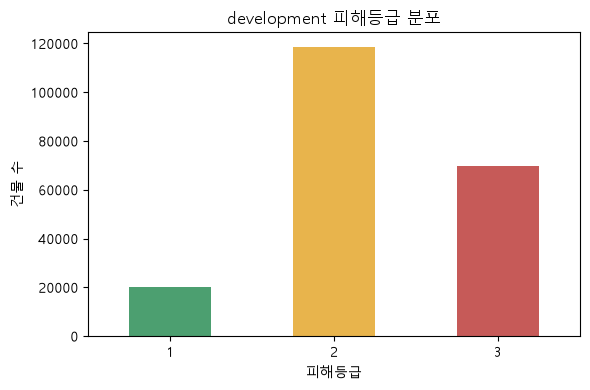

In [3]:
grade_summary = (
    dev["damage_grade"]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

grade_summary["ratio"] = grade_summary["count"] / len(dev)
grade_summary["percent"] = grade_summary["ratio"] * 100

display(grade_summary)

save_table(
    grade_summary.reset_index(),
    "dev_grade_distribution"
)

numeric_by_grade = (
    dev.groupby("damage_grade")[NUM]
    .agg(["mean", "median"])
    .round(2)
)

display(numeric_by_grade)

save_table(
    dev.groupby("damage_grade")[NUM]
    .mean()
    .reset_index(),
    "dev_grade_numeric_means"
)

print("development age=995 건수:", (dev["age"] == 995).sum())
print("development 입력 38열 중복 행 수:", X.duplicated().sum())

display(
    dev["age"]
    .value_counts()
    .sort_index()
    .tail(10)
)

fig, ax = plt.subplots(figsize=(6, 4))

grade_summary["count"].plot(
    kind="bar",
    ax=ax,
    color=["#4c9f70", "#e8b44c", "#c65a58"]
)

ax.set_title("development 피해등급 분포")
ax.set_xlabel("피해등급")
ax.set_ylabel("건물 수")

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "dev_grade_distribution.png", dpi=150)
plt.show()

In [4]:
def grade_table(data, columns):
    """집단별 1·2·3등급 건수와 비율을 계산합니다."""

    table = (
        data.groupby(
            columns + ["damage_grade"],
            observed=True
        )
        .size()
        .unstack(fill_value=0)
    )

    table = table.reindex(columns=LABELS, fill_value=0)
    table.columns = ["count_1", "count_2", "count_3"]
    table["n"] = table.sum(axis=1)

    overall_ratio = data["damage_grade"].value_counts(normalize=True)

    for grade in LABELS:
        table[f"rate_{grade}"] = table[f"count_{grade}"] / table["n"]

        # 표본이 적은 집단은 전체 비율 쪽으로 완만하게 축소
        table[f"smoothed_{grade}"] = (
            table[f"count_{grade}"]
            + 30 * overall_ratio.get(grade, 0)
        ) / (table["n"] + 30)

    return table.reset_index()


def export_rankings(data, prefix):
    """지역 단계별·등급별 건수/비율 TOP5를 저장합니다."""

    all_top = []

    for geo in GEO:
        table = grade_table(data, [geo])
        save_table(table, f"{prefix}_{geo}_all_grades")

        for grade in LABELS:
            ranking_rules = [
                ("count", f"count_{grade}", 1),
                ("rate_raw", f"rate_{grade}", 1),
                ("rate_n30", f"rate_{grade}", 30),
                ("smoothed", f"smoothed_{grade}", 1)
            ]

            for kind, column, minimum in ranking_rules:
                top = (
                    table[table["n"] >= minimum]
                    .sort_values(
                        [column, "n", geo],
                        ascending=[False, False, True]
                    )
                    .head(5)
                    .copy()
                )

                top = top.rename(columns={geo: "region"})
                top["level"] = geo
                top["grade"] = grade
                top["ranking"] = kind

                all_top.append(top)

    result = pd.concat(all_top, ignore_index=True)
    save_table(result, f"{prefix}_geo_top5")

    return result


top5_dev = export_rankings(dev, "dev")

for geo in GEO:
    for grade in [3, 2]:
        print(f"\n[{geo} / {grade}등급]")

        selected = top5_dev[
            (top5_dev["level"] == geo)
            & (top5_dev["grade"] == grade)
            & top5_dev["ranking"].isin(["count", "rate_n30"])
        ]

        display(
            selected[
                ["ranking", "region", "n", f"count_{grade}", f"rate_{grade}"]
            ]
        )


[geo_level_1_id / 3등급]


,ranking,region,n,count_3,rate_3
40,count,17,17370,14013,0.806736
41,count,8,15331,7980,0.520514
42,count,10,17742,7062,0.398039
43,count,21,11864,6897,0.581339
44,count,7,15222,5394,0.354356
50,rate_n30,17,17370,14013,0.806736
51,rate_n30,18,2530,1858,0.734387
52,rate_n30,21,11864,6897,0.581339
53,rate_n30,8,15331,7980,0.520514
54,rate_n30,27,10015,4845,0.483774



[geo_level_1_id / 2등급]


,ranking,region,n,count_2,rate_2
20,count,6,19473,12984,0.666769
21,count,26,18038,10087,0.559208
22,count,10,17742,9706,0.547063
23,count,20,13786,9467,0.686711
24,count,7,15222,8975,0.589607
30,rate_n30,29,329,288,0.875380
31,rate_n30,30,2103,1677,0.797432
32,rate_n30,25,4536,3529,0.777998
33,rate_n30,0,3212,2476,0.770859
34,rate_n30,4,11605,8894,0.766394



[geo_level_2_id / 3등급]


...

,ranking,region,n,count_2,rate_2
80,count,39,3229,1471,0.455559
81,count,158,2008,1367,0.680777
82,count,1387,1647,1156,0.701882
83,count,181,1690,1059,0.626627
84,count,673,1356,966,0.712389
90,rate_n30,1405,39,38,0.974359
91,rate_n30,750,38,37,0.973684
92,rate_n30,365,35,34,0.971429
93,rate_n30,725,69,67,0.971014
94,rate_n30,625,91,88,0.967033



[geo_level_3_id / 3등급]


,ranking,region,n,count_3,rate_3
160,count,8236,245,132,0.538776
161,count,4391,114,99,0.868421
162,count,2386,160,97,0.606250
163,count,5957,99,97,0.979798
164,count,2537,216,93,0.430556
170,rate_n30,9880,68,68,1.000000
171,rate_n30,1408,64,64,1.000000
172,rate_n30,4476,56,56,1.000000
173,rate_n30,3953,50,50,1.000000
174,rate_n30,5807,49,49,1.000000



[geo_level_3_id / 2등급]


,ranking,region,n,count_2,rate_2
140,count,621,436,282,0.646789
141,count,633,518,223,0.430502
142,count,2005,378,193,0.510582
143,count,9229,300,192,0.640000
144,count,2452,280,179,0.639286
150,rate_n30,842,42,42,1.000000
151,rate_n30,2623,40,40,1.000000
152,rate_n30,4354,39,39,1.000000
153,rate_n30,4319,36,36,1.000000
154,rate_n30,9575,32,32,1.000000


In [5]:
geo3_table = grade_table(dev, ["geo_level_3_id"])
overall_grade3_ratio = (dev["damage_grade"] == 3).mean()

sensitivity_rows = []

for alpha in [10, 30, 100]:
    temp = geo3_table.copy()

    temp["adjusted_rate3"] = (
        temp["count_3"] + alpha * overall_grade3_ratio
    ) / (temp["n"] + alpha)

    sensitivity_rows.append(
        temp.nlargest(5, "adjusted_rate3").assign(alpha=alpha)
    )

sensitivity = pd.concat(sensitivity_rows, ignore_index=True)

display(
    sensitivity[
        ["alpha", "geo_level_3_id", "n", "count_3", "rate_3", "adjusted_rate3"]
    ]
)

save_table(sensitivity, "dev_sparse_smoothing_sensitivity")

# 하위 지역 하나가 상위 지역 하나에만 속하는지 확인
hierarchy = dev.groupby("geo_level_3_id")[GEO[:2]].nunique().max()

print("하위 지역 하나가 속한 상위 지역 수(최대):")
display(hierarchy)

,alpha,geo_level_3_id,n,count_3,rate_3,adjusted_rate3
0,10,5957,99,97,0.979798,0.920613
1,10,1743,93,91,0.978495,0.915988
2,10,9880,68,68,1.000000,0.914703
3,10,4221,77,76,0.987013,0.912032
4,10,7851,88,86,0.977273,0.911702
5,30,5957,99,97,0.979798,0.829770
6,30,1743,93,91,0.978495,0.821467
7,30,7851,88,86,0.977273,0.813902
8,30,4221,77,76,0.987013,0.804116
9,30,9880,68,68,1.000000,0.796330


하위 지역 하나가 속한 상위 지역 수(최대):


geo_level_1_id    1
geo_level_2_id    1
dtype: int64

In [6]:
MATERIAL = [c for c in X.columns if c.startswith("has_superstructure_")]

ARCH = [
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "land_surface_condition"
]


def export_elements(data, prefix):
    rows = []

    # 자재 사용 건물의 피해등급 분포
    for material in MATERIAL:
        part = data[data[material] == 1]

        row = {
            "element": material,
            "value": "1",
            "family": "material",
            "n": len(part)
        }

        for grade in LABELS:
            count = int((part["damage_grade"] == grade).sum())
            row[f"count_{grade}"] = count
            row[f"rate_{grade}"] = count / max(len(part), 1)

        rows.append(row)

    # 기초·지붕·바닥 등 건축 요소
    for column in ARCH:
        table = grade_table(data, [column])
        table = table.rename(columns={column: "value"})
        table["element"] = column
        table["family"] = "architecture"
        rows.extend(table.to_dict("records"))

    elements = pd.DataFrame(rows)
    save_table(elements, f"{prefix}_element_all_grades")

    top_rows = []

    for family in ["material", "architecture"]:
        for grade in LABELS:
            for kind, minimum in [("count", 1), ("rate", 30)]:
                top = (
                    elements[
                        (elements["family"] == family)
                        & (elements["n"] >= minimum)
                    ]
                    .nlargest(5, f"{kind}_{grade}")
                    .copy()
                )

                top["grade"] = grade
                top["ranking"] = kind
                top_rows.append(top)

    element_top5 = pd.concat(top_rows, ignore_index=True)
    save_table(element_top5, f"{prefix}_element_top5")

    # 지역 × 자재
    combination_rows = []

    for geo in GEO:
        for material in MATERIAL:
            part = data[data[material] == 1]
            table = grade_table(part, [geo])
            table = table.rename(columns={geo: "region"})
            table["level"] = geo
            table["material"] = material
            combination_rows.append(table)

    combinations = pd.concat(combination_rows, ignore_index=True)
    save_table(combinations, f"{prefix}_geo_material_all_grades")

    combination_top5 = (
        combinations[combinations["n"] >= 30]
        .sort_values("rate_3", ascending=False)
        .groupby("level", sort=False)
        .head(5)
    )

    save_table(combination_top5, f"{prefix}_geo_material_top5_rate3")

    return elements, element_top5, combination_top5


elements, element_top5, combination_top5 = export_elements(dev, "dev")

for family in ["material", "architecture"]:
    for grade in [3, 2]:
        print(f"\n[{family} / {grade}등급]")

        display(
            element_top5[
                (element_top5["family"] == family)
                & (element_top5["grade"] == grade)
            ][
                ["ranking", "element", "value", "n", f"count_{grade}", f"rate_{grade}"]
            ]
        )

print("\n[지역 × 자재 / 3등급 비율 TOP5]")
display(combination_top5)


[material / 3등급]


,ranking,element,value,n,count_3,rate_3
20,count,has_superstructure_mud_mortar_stone,1,158774,60592,0.381624
21,count,has_superstructure_timber,1,53163,14944,0.281098
22,count,has_superstructure_adobe_mud,1,18529,6931,0.374062
23,count,has_superstructure_mud_mortar_brick,1,14276,4395,0.307859
24,count,has_superstructure_bamboo,1,17783,4252,0.239105
25,rate,has_superstructure_stone_flag,1,7129,3387,0.475102
26,rate,has_superstructure_mud_mortar_stone,1,158774,60592,0.381624
27,rate,has_superstructure_adobe_mud,1,18529,6931,0.374062
28,rate,has_superstructure_mud_mortar_brick,1,14276,4395,0.307859
29,rate,has_superstructure_timber,1,53163,14944,0.281098



[material / 2등급]


,ranking,element,value,n,count_2,rate_2
10,count,has_superstructure_mud_mortar_stone,1,158774,91185,0.574307
11,count,has_superstructure_timber,1,53163,32079,0.603408
12,count,has_superstructure_bamboo,1,17783,11256,0.632964
13,count,has_superstructure_adobe_mud,1,18529,11117,0.599978
14,count,has_superstructure_mud_mortar_brick,1,14276,9387,0.657537
15,rate,has_superstructure_cement_mortar_stone,1,3804,2596,0.682440
16,rate,has_superstructure_mud_mortar_brick,1,14276,9387,0.657537
17,rate,has_superstructure_bamboo,1,17783,11256,0.632964
18,rate,has_superstructure_timber,1,53163,32079,0.603408
19,rate,has_superstructure_adobe_mud,1,18529,11117,0.599978



[architecture / 3등급]


,ranking,element,value,n,count_3,rate_3
50,count,plan_configuration,d,200031,67378,0.336838
51,count,foundation_type,r,175259,66352,0.378594
52,count,ground_floor_type,f,167644,61757,0.368382
53,count,land_surface_condition,t,173392,58141,0.335315
54,count,position,s,161689,52907,0.327215
55,rate,plan_configuration,q,4544,1855,0.408231
56,rate,position,t,34271,13410,0.391293
57,rate,roof_type,q,49319,18902,0.383260
58,rate,foundation_type,r,175259,66352,0.378594
59,rate,other_floor_type,x,34735,13054,0.375817



[architecture / 2등급]


,ranking,element,value,n,count_2,rate_2
40,count,plan_configuration,d,200031,113992,0.569872
41,count,foundation_type,r,175259,100366,0.572672
42,count,land_surface_condition,t,173392,97680,0.563348
43,count,ground_floor_type,f,167644,95914,0.572129
44,count,position,s,161689,92851,0.574257
45,rate,plan_configuration,m,35,27,0.771429
46,rate,position,o,1874,1299,0.693170
47,rate,ground_floor_type,m,395,262,0.663291
48,rate,plan_configuration,u,2947,1938,0.657618
49,rate,plan_configuration,s,280,177,0.632143



[지역 × 자재 / 3등급 비율 TOP5]


,region,count_1,count_2,count_3,n,rate_1,smoothed_1,rate_2,smoothed_2,rate_3,smoothed_3,level,material
19395,5096,0,0,31,31,0.000000,0.009934,0.000000,0.248213,1.000000,0.741853,geo_level_3_id,has_superstructure_stone_flag
19425,5370,0,0,33,33,0.000000,0.009619,0.000000,0.240333,1.000000,0.750048,geo_level_3_id,has_superstructure_stone_flag
19541,6770,0,0,33,33,0.000000,0.009619,0.000000,0.240333,1.000000,0.750048,geo_level_3_id,has_superstructure_stone_flag
16094,7142,0,0,40,40,0.000000,0.018887,0.000000,0.246132,1.000000,0.734982,geo_level_3_id,has_superstructure_mud_mortar_stone
4559,648,0,0,74,74,0.000000,0.033316,0.000000,0.174060,1.000000,0.792624,geo_level_2_id,has_superstructure_timber
13546,4476,0,0,56,56,0.000000,0.015373,0.000000,0.200340,1.000000,0.784288,geo_level_3_id,has_superstructure_mud_mortar_stone
4298,233,0,0,71,71,0.000000,0.034305,0.000000,0.179230,1.000000,0.786465,geo_level_2_id,has_superstructure_timber
5487,123,0,0,97,97,0.000000,0.081944,0.000000,0.123935,1.000000,0.794121,geo_level_2_id,has_superstructure_rc_non_engineered
4676,817,0,0,142,142,0.000000,0.020144,0.000000,0.105246,1.000000,0.874610,geo_level_2_id,has_superstructure_timber
2350,421,0,0,80,80,0.000000,0.005509,0.000000,0.137645,1.000000,0.856846,geo_level_2_id,has_superstructure_stone_flag


Pearson 상관계수


,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count_floors_pre_eq,1.000,0.086,0.100,0.774,0.087
age,0.086,1.000,-0.004,0.061,0.005
area_percentage,0.100,-0.004,1.000,0.196,0.089
height_percentage,0.774,0.061,0.196,1.000,0.066
count_families,0.087,0.005,0.089,0.066,1.000


Spearman 상관계수


,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count_floors_pre_eq,1.000,0.256,0.125,0.755,0.078
age,0.256,1.000,-0.015,0.198,0.047
area_percentage,0.125,-0.015,1.000,0.210,0.078
height_percentage,0.755,0.198,0.210,1.000,0.064
count_families,0.078,0.047,0.078,0.064,1.000


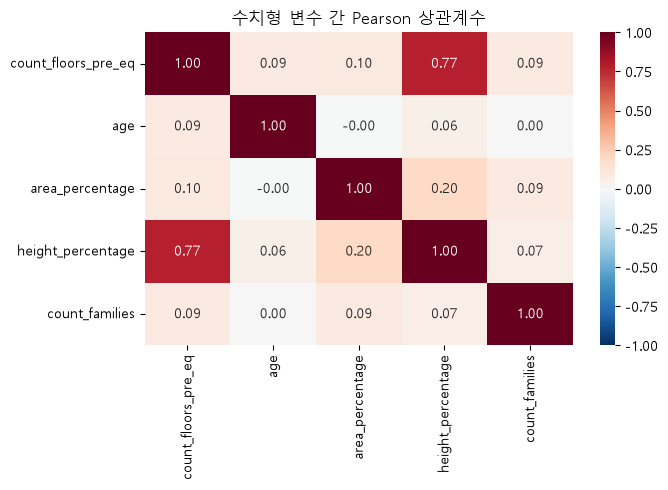

,feature,spearman,p_value
1,age,0.173796,0.000000e+00
0,count_floors_pre_eq,0.138893,0.000000e+00
3,height_percentage,0.078995,9.220407e-286
4,count_families,0.059857,9.458966e-165
2,area_percentage,-0.101433,0.000000e+00


In [7]:
pearson_corr = dev[NUM].corr()
spearman_corr = dev[NUM].corr(method="spearman")

print("Pearson 상관계수")
display(pearson_corr.round(3))

print("Spearman 상관계수")
display(spearman_corr.round(3))

save_table(pearson_corr.reset_index(), "dev_numeric_pearson")
save_table(spearman_corr.reset_index(), "dev_numeric_spearman")

plt.figure(figsize=(7, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("수치형 변수 간 Pearson 상관계수")
plt.tight_layout()
plt.show()

target_corr_rows = []

for column in NUM:
    correlation, p_value = spearmanr(dev[column], dev["damage_grade"])

    target_corr_rows.append({
        "feature": column,
        "spearman": correlation,
        "p_value": p_value
    })

target_corr = pd.DataFrame(target_corr_rows)

display(target_corr.sort_values("spearman", ascending=False))
save_table(target_corr, "dev_target_spearman")

In [8]:
def association(a, b):
    table = pd.crosstab(a, b)

    if min(table.shape) < 2:
        return {"p_value": np.nan, "cramers_v_corrected": np.nan}

    chi2, p_value, dof, expected = chi2_contingency(table, correction=False)

    n = table.to_numpy().sum()
    r, k = table.shape

    # 편향을 보정한 Cramer's V
    phi = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))

    denominator = min(
        k - 1 - (k - 1) ** 2 / (n - 1),
        r - 1 - (r - 1) ** 2 / (n - 1)
    )

    corrected_v = np.sqrt(phi / denominator) if denominator > 0 else np.nan

    return {
        "chi2": chi2,
        "p_value": p_value,
        "cramers_v_corrected": corrected_v,
        "expected_lt5_ratio": float((expected < 5).mean()),
        "expected_min": float(expected.min()),
        "approximation_ok": bool(
            expected.min() >= 1 and (expected < 5).mean() <= 0.2
        )
    }


cat_cols = GEO + [
    c for c in X.columns
    if c not in GEO
    and (c.startswith("has_") or not pd.api.types.is_numeric_dtype(X[c]))
]

association_rows = []

for column in cat_cols:
    association_rows.append({
        "feature_a": column,
        "feature_b": "damage_grade",
        **association(dev[column], dev["damage_grade"])
    })

for geo in GEO:
    for material in MATERIAL:
        association_rows.append({
            "feature_a": geo,
            "feature_b": material,
            **association(dev[geo], dev[material])
        })

association_table = pd.DataFrame(association_rows)

# Benjamini-Hochberg FDR 보정
sorted_p = association_table["p_value"].dropna().sort_values()
number_of_tests = len(sorted_p)
rank = np.arange(1, number_of_tests + 1)

adjusted = sorted_p.to_numpy() * number_of_tests / rank
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]

association_table.loc[sorted_p.index, "p_fdr_bh"] = np.minimum(adjusted, 1)

save_table(association_table, "dev_chi_square")

display(
    association_table[association_table["feature_b"] == "damage_grade"]
    .sort_values("cramers_v_corrected", ascending=False)
)

,feature_a,feature_b,chi2,p_value,cramers_v_corrected,expected_lt5_ratio,expected_min,approximation_ok,p_fdr_bh
2,geo_level_3_id,damage_grade,148997.304787,0.000000e+00,0.550357,0.636073,0.096407,False,0.000000e+00
1,geo_level_2_id,damage_grade,107383.341996,0.000000e+00,0.500792,0.231297,0.096407,False,0.000000e+00
0,geo_level_1_id,damage_grade,57883.677064,0.000000e+00,0.372398,0.000000,20.052724,True,0.000000e+00
11,has_superstructure_mud_mortar_stone,damage_grade,23341.078508,0.000000e+00,0.334588,0.000000,4792.022707,True,0.000000e+00
4,foundation_type,damage_grade,38882.960536,0.000000e+00,0.305344,0.000000,114.821129,True,0.000000e+00
15,has_superstructure_cement_mortar_brick,damage_grade,16379.055656,0.000000e+00,0.280277,0.000000,1509.545961,True,0.000000e+00
6,ground_floor_type,damage_grade,29111.230608,0.000000e+00,0.264196,0.000000,38.080895,True,0.000000e+00
7,other_floor_type,damage_grade,25093.927722,0.000000e+00,0.245294,0.000000,927.631322,True,0.000000e+00
5,roof_type,damage_grade,24100.715142,0.000000e+00,0.240400,0.000000,1250.981504,True,0.000000e+00
19,has_superstructure_rc_engineered,damage_grade,11730.461471,0.000000e+00,0.237186,0.000000,318.144186,True,0.000000e+00


## 3. 파생변수와 fold 내부 전처리

`fit_features`는 학습 fold에서만 규칙(범주 목록, 지역 건수, 지역별 진흙-석재 비율)을 정하고, `transform_features`는 그 규칙을 검증 fold에 그대로 적용합니다. 정답(y)은 사용하지 않습니다.
수정: 학습 fold에 없던 범주는 먼저 NaN으로 바꾼 뒤 범주형으로 변환합니다(test_5의 Pandas4Warning 원인).

In [9]:
JOINT5 = {
    "geo1_x_mudstone": ("geo_level_1_id", "has_superstructure_mud_mortar_stone"),
    "foundation_x_mudstone": ("foundation_type", "has_superstructure_mud_mortar_stone"),
    "roof_x_rceng": ("roof_type", "has_superstructure_rc_engineered"),
    "groundfloor_x_cementbrick": ("ground_floor_type", "has_superstructure_cement_mortar_brick"),
    "otherfloor_x_mudstone": ("other_floor_type", "has_superstructure_mud_mortar_stone")
}

CONCRETE = [
    "has_superstructure_cement_mortar_stone",
    "has_superstructure_cement_mortar_brick",
    "has_superstructure_rc_non_engineered",
    "has_superstructure_rc_engineered"
]

MUD = [
    "has_superstructure_adobe_mud",
    "has_superstructure_mud_mortar_stone",
    "has_superstructure_mud_mortar_brick"
]

STRUCT_PAIRS = {
    "foundation_roof": ("foundation_type", "roof_type"),
    "ground_other_floor": ("ground_floor_type", "other_floor_type"),
    "foundation_ground": ("foundation_type", "ground_floor_type"),
    "surface_ground": ("land_surface_condition", "ground_floor_type")
}


def add_features(X, mode):
    """건물 한 행의 입력만으로 만들 수 있는 파생변수. 정답 y는 쓰지 않습니다."""

    result = X.copy()

    if mode == "raw":
        return result

    material_cols = [c for c in result.columns if c.startswith("has_superstructure_")]

    # 이전 실험(nepal_interaction_sampling_experiments.py)의 결합변수 5개
    if mode == "joint5":
        for name, (left, right) in JOINT5.items():
            result[name] = result[left].astype(str) + "|" + result[right].astype(str)

        return result

    # modeling.ipynb의 파생변수 중 정답을 쓰지 않는 것만
    if mode == "struct":
        secondary_cols = [c for c in result.columns if c.startswith("has_secondary_use_")]

        result["material_count"] = result[material_cols].sum(axis=1)
        result["secondary_use_count"] = result[secondary_cols].sum(axis=1)
        result["concrete_count"] = result[CONCRETE].sum(axis=1)
        result["mud_count"] = result[MUD].sum(axis=1)

        result["height_per_floor"] = (
            result["height_percentage"]
            / result["count_floors_pre_eq"].clip(lower=1)
        )

        result["height_area_ratio"] = (
            result["height_percentage"]
            / result["area_percentage"].clip(lower=1)
        )

        for name, (left, right) in STRUCT_PAIRS.items():
            result[name] = result[left].astype(str) + "|" + result[right].astype(str)

        return result

    result["material_count"] = result[material_cols].sum(axis=1)

    result["height_per_floor"] = (
        result["height_percentage"]
        / result["count_floors_pre_eq"].clip(lower=1)
    )

    result["height_area_ratio"] = (
        result["height_percentage"]
        / result["area_percentage"].clip(lower=1)
    )

    # 원래 age 값은 유지하고 특수값 여부만 추가
    result["age_is_995"] = (result["age"] == 995).astype(int)

    result["foundation_roof"] = (
        result["foundation_type"].astype(str)
        + "|"
        + result["roof_type"].astype(str)
    )

    result["geo1_mudstone"] = (
        result["geo_level_1_id"].astype(str)
        + "|"
        + result["has_superstructure_mud_mortar_stone"].astype(str)
    )

    result["geo2_foundation"] = (
        result["geo_level_2_id"].astype(str)
        + "|"
        + result["foundation_type"].astype(str)
    )

    return result


def to_known_categorical(values, categories):
    """학습 fold에 없던 값은 NaN으로 바꾼 뒤 범주형으로 변환합니다."""

    known = values.where(values.isin(categories))

    return pd.Categorical(known, categories=categories)


def fit_features(X, mode):
    """학습 fold에서 전처리 규칙을 정하고, 변환된 데이터와 규칙을 반환합니다."""

    result = add_features(X, mode)

    state = {
        "mode": mode,
        "counts": {},
        "material_means": {},
        "categories": {}
    }

    if mode == "geo":
        material = "has_superstructure_mud_mortar_stone"
        state["global_material"] = float(X[material].mean())

        for geo in GEO:
            counts = X[geo].value_counts()
            material_means = X.groupby(geo)[material].mean()

            state["counts"][geo] = counts
            state["material_means"][geo] = material_means

            result[f"{geo}_count"] = X[geo].map(counts).astype(float)
            result[f"{geo}_mud_rate"] = X[geo].map(material_means)

    categorical = [
        c for c in result.columns
        if c in GEO or not pd.api.types.is_numeric_dtype(result[c])
    ]

    for column in categorical:
        categories = sorted(result[column].dropna().unique().tolist())
        state["categories"][column] = categories
        result[column] = pd.Categorical(result[column], categories=categories)

    state["columns"] = result.columns.tolist()

    return result, state


def transform_features(X, state):
    """학습 fold에서 정한 규칙으로 검증 fold를 변환합니다."""

    result = add_features(X, state["mode"])

    for geo, counts in state["counts"].items():
        # 학습 fold에 없던 지역은 건수 0
        result[f"{geo}_count"] = X[geo].map(counts).fillna(0).astype(float)

        # 학습 fold에 없던 지역은 학습 fold 전체 비율
        result[f"{geo}_mud_rate"] = (
            X[geo]
            .map(state["material_means"][geo])
            .fillna(state["global_material"])
        )

    for column, categories in state["categories"].items():
        result[column] = to_known_categorical(result[column], categories)

    return result[state["columns"]]


for mode in ["raw", "basic", "geo", "joint5", "struct"]:
    sample, state = fit_features(X.iloc[folds[0][0]], mode)
    print(mode, "입력 변수 수:", sample.shape[1])

# 처음 보는 범주 처리 확인: 학습 fold에 없는 geo_level_3는 NaN이 되어야 함
_, state0 = fit_features(X.iloc[folds[0][0]], "raw")
valid0 = transform_features(X.iloc[folds[0][1]], state0)
unseen_geo3 = ~X.iloc[folds[0][1]]["geo_level_3_id"].isin(state0["categories"]["geo_level_3_id"])

assert valid0["geo_level_3_id"].isna().sum() == unseen_geo3.sum()
print("fold 0 검증 행 중 학습 fold에 없던 geo_level_3:", int(unseen_geo3.sum()))

raw 입력 변수 수: 38


basic 입력 변수 수: 45


geo 입력 변수 수: 51


joint5 입력 변수 수: 43


struct 입력 변수 수: 48
fold 0 검증 행 중 학습 fold에 없던 geo_level_3: 306


## 4. 모델·학습·평가 함수

수정: RandomForest에는 geo ID를 원-핫 대신 숫자로 넣습니다. 약 13,000개의 희소 더미 열 때문에 분할이 망가지는 것을 막기 위해서입니다. 나머지 모델 설정은 test_5와 같습니다.

In [10]:
def geo_to_number(frame):
    """범주형 geo ID를 숫자로 바꿉니다. 학습 fold에 없던 지역은 NaN으로 둡니다."""

    return np.column_stack([
        pd.to_numeric(frame[c].astype(object), errors="coerce")
        for c in frame.columns
    ]).astype(float)


def make_model(kind, X, method="none", params=None):
    params = {} if params is None else params.copy()

    class_weight = None

    if method in ["balanced", "under_partial_balanced"]:
        class_weight = "balanced"

    elif method == "grade3":
        class_weight = {1: 1.5, 2: 1.0, 3: 1.2}

    # LightGBM: pandas category를 범주형 변수로 직접 사용
    if kind == "lgbm":
        settings = {
            "n_estimators": 100,
            "random_state": SEED,
            "n_jobs": 4,
            "verbosity": -1,
            "deterministic": True,
            "force_col_wise": True,
            "class_weight": class_weight
        }

        settings.update(params)

        return LGBMClassifier(**settings)

    # 최빈 등급만 예측하는 기준 모델
    if kind == "dummy":
        return DummyClassifier(strategy="most_frequent")

    cat = [c for c in X.columns if isinstance(X[c].dtype, pd.CategoricalDtype)]
    num = [c for c in X.columns if c not in cat]

    one_hot = OneHotEncoder(handle_unknown="ignore", dtype=np.float32)

    if kind == "logistic":
        preprocess = ColumnTransformer([
            (
                "num",
                Pipeline([
                    ("fill", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler())
                ]),
                num
            ),
            ("cat", one_hot, cat)
        ])

        model = LogisticRegression(
            solver="saga",
            max_iter=600,
            tol=0.001,
            random_state=SEED,
            class_weight=class_weight
        )

    elif kind == "forest":
        geo_cols = [c for c in cat if c in GEO]
        other_cat = [c for c in cat if c not in GEO]

        preprocess = ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), num),
            (
                "geo",
                Pipeline([
                    ("number", FunctionTransformer(geo_to_number)),
                    ("fill", SimpleImputer(strategy="median"))
                ]),
                geo_cols
            ),
            ("cat", one_hot, other_cat)
        ])

        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=22,
            min_samples_leaf=3,
            n_jobs=4,
            random_state=SEED,
            class_weight=class_weight
        )

    else:
        raise ValueError(f"알 수 없는 모델: {kind}")

    return Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])


def train_model(X, y, config):
    # 학습 fold로만 전처리 규칙 결정
    train_x, state = fit_features(X, config["features"])

    method = config["method"]

    model = make_model(config["kind"], train_x, method, config.get("params"))

    weights = None

    # 희소 지역 가중치: 학습 fold의 지역 건물 수 기준, 1~3배로 제한
    if method == "rare_region":
        counts = X["geo_level_3_id"].value_counts()
        row_counts = X["geo_level_3_id"].map(counts)

        weights = np.sqrt(30 / row_counts).clip(1, 3).to_numpy()
        weights = weights / weights.mean()

    # 샘플링은 학습 fold 안에서만 수행
    if method in ["under_partial", "under_partial_balanced", "under_full", "over_full"]:
        if method in ["under_partial", "under_partial_balanced"]:
            cap = min(int((y == 2).sum()), int((y == 3).sum()))

            sampler = RandomUnderSampler(
                sampling_strategy={2: cap},
                random_state=SEED
            )

        elif method == "under_full":
            sampler = RandomUnderSampler(random_state=SEED)

        else:
            sampler = RandomOverSampler(random_state=SEED)

        train_x, y = sampler.fit_resample(train_x, y)

    if weights is None:
        model.fit(train_x, y)

    else:
        model.fit(train_x, y, sample_weight=weights)

    return {
        "model": model,
        "state": state,
        "config": config,
        "train_n": len(y)
    }


def predict_model(bundle, X):
    transformed = transform_features(X, bundle["state"])

    return bundle["model"].predict(transformed)


def metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    report = classification_report(
        y_true,
        y_pred,
        labels=LABELS,
        output_dict=True,
        zero_division=0
    )

    result = {
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "micro_f1": f1_score(y_true, y_pred, labels=LABELS, average="micro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred)
    }

    for grade in LABELS:
        for metric_name in ["precision", "recall", "f1-score"]:
            result[f"{metric_name}_{grade}"] = report[str(grade)][metric_name]

    # 실제 3등급을 낮게 예측한 비율
    n_grade3 = max(cm[2].sum(), 1)

    result["error_3_to_2"] = cm[2, 1] / n_grade3
    result["error_3_to_1"] = cm[2, 0] / n_grade3

    return result

## 5. 1단계 CV: 모든 기본 후보를 같은 5-fold로 비교

test_5에서는 val로 먼저 걸렀지만, 여기서는 기준선과 이전 실험에서 가져온 후보를 포함한 15개를 모두 같은 5-fold로 평가합니다.
`diff_vs_raw`는 LGBM_raw와 fold별로 짝지은 Macro F1 차이이고, `wins_vs_raw`는 5개 fold 중 이긴 횟수입니다.

In [11]:
cv_rows = []
oof = {}


def run_cv(config):
    """저장된 5-fold로 학습·예측하고 fold별 지표와 OOF 예측을 남깁니다."""

    pred = np.zeros(len(X), dtype=int)

    for fold_number, (tr, va) in enumerate(folds):
        started = time.perf_counter()

        bundle = train_model(X.iloc[tr], y.iloc[tr], config)
        fold_pred = predict_model(bundle, X.iloc[va])
        pred[va] = fold_pred

        cv_rows.append({
            "name": config["name"],
            "fold": fold_number,
            "train_n": bundle["train_n"],
            "features_n": len(bundle["state"]["columns"]),
            **metrics(y.iloc[va], fold_pred),
            "seconds": time.perf_counter() - started
        })

    assert set(np.unique(pred)) <= set(LABELS)
    oof[config["name"]] = pred

    save_table(pd.DataFrame(cv_rows), "cv_folds")

    scores = [r["macro_f1"] for r in cv_rows if r["name"] == config["name"]]
    print(f"{config['name']:<22} Macro F1 {np.mean(scores):.5f} ± {np.std(scores, ddof=1):.5f}", flush=True)


def summarize(cv_table, baseline="LGBM_raw"):
    """후보별 평균·표준편차와, 기준선 대비 fold별 짝지은 차이를 계산합니다."""

    wide = cv_table.pivot(index="fold", columns="name", values="macro_f1")
    diff = wide.sub(wide[baseline], axis=0)

    summary = (
        cv_table.groupby("name")
        .agg(
            mean=("macro_f1", "mean"),
            std=("macro_f1", "std"),
            recall_1=("recall_1", "mean"),
            recall_2=("recall_2", "mean"),
            recall_3=("recall_3", "mean"),
            error_3_to_2=("error_3_to_2", "mean"),
            error_3_to_1=("error_3_to_1", "mean"),
            train_n=("train_n", "mean"),
            seconds=("seconds", "sum")
        )
        .assign(
            diff_vs_raw=diff.mean(),
            diff_std=diff.std(),
            wins_vs_raw=(diff > 0).sum()
        )
        .reset_index()
        .sort_values(["mean", "std", "name"], ascending=[False, True, True])
    )

    return summary


configs = [
    {"name": "Dummy", "kind": "dummy", "features": "raw", "method": "none"},
    {"name": "Logistic", "kind": "logistic", "features": "raw", "method": "none"},
    {"name": "RandomForest", "kind": "forest", "features": "raw", "method": "none"}
]

# LightGBM 파생변수 비교
for mode in ["raw", "basic", "geo", "joint5", "struct"]:
    configs.append({
        "name": f"LGBM_{mode}",
        "kind": "lgbm",
        "features": mode,
        "method": "none"
    })

# LightGBM 불균형 처리 비교 (입력은 raw로 고정)
for method in [
    "balanced",
    "grade3",
    "under_partial",
    "under_partial_balanced",
    "under_full",
    "over_full",
    "rare_region"
]:
    configs.append({
        "name": f"LGBM_{method}",
        "kind": "lgbm",
        "features": "raw",
        "method": method
    })

for config in configs:
    run_cv(config)

stage1 = summarize(pd.DataFrame(cv_rows))
save_table(stage1, "cv_summary_stage1")
display(stage1.round(5))

Dummy                  Macro F1 0.24174 ± 0.00000


Logistic               Macro F1 0.66939 ± 0.00274


RandomForest           Macro F1 0.61490 ± 0.00425


LGBM_raw               Macro F1 0.69860 ± 0.00284


LGBM_basic             Macro F1 0.69941 ± 0.00318


...

LGBM_under_partial_balanced Macro F1 0.67464 ± 0.00198


LGBM_under_full        Macro F1 0.65396 ± 0.00165


LGBM_over_full         Macro F1 0.68068 ± 0.00193


LGBM_rare_region       Macro F1 0.69715 ± 0.00239


,name,mean,std,recall_1,recall_2,recall_3,error_3_to_2,error_3_to_1,train_n,seconds,diff_vs_raw,diff_std,wins_vs_raw
4,LGBM_grade3,0.70560,0.00405,0.63685,0.79851,0.67871,0.31062,0.01068,166784.0,124.98990,0.00700,0.00137,5
9,LGBM_struct,0.69948,0.00259,0.55520,0.84022,0.64471,0.34794,0.00735,166784.0,133.43667,0.00088,0.00080,4
2,LGBM_basic,0.69941,0.00318,0.55421,0.84055,0.64437,0.34825,0.00738,166784.0,368.46426,0.00081,0.00083,4
3,LGBM_geo,0.69894,0.00343,0.55336,0.84025,0.64384,0.34868,0.00748,166784.0,141.94981,0.00034,0.00111,3
8,LGBM_raw,0.69860,0.00284,0.55207,0.84059,0.64366,0.34901,0.00732,166784.0,1701.10560,0.00000,0.00000,0
11,LGBM_under_partial,0.69841,0.00247,0.66406,0.72787,0.74466,0.24330,0.01204,127717.6,106.87468,-0.00019,0.00115,1
5,LGBM_joint5,0.69759,0.00369,0.55003,0.83992,0.64361,0.34896,0.00744,166784.0,127.13805,-0.00102,0.00150,1
7,LGBM_rare_region,0.69715,0.00239,0.55227,0.83755,0.64450,0.34797,0.00754,166784.0,108.65192,-0.00146,0.00088,0
6,LGBM_over_full,0.68068,0.00193,0.81790,0.67194,0.73351,0.23745,0.02904,284656.8,137.47295,-0.01792,0.00119,0
1,LGBM_balanced,0.67939,0.00172,0.82830,0.66510,0.73817,0.23066,0.03117,166784.0,128.43525,-0.01922,0.00161,0


## 6. 2단계 CV: 1단계 최고 LightGBM 설정 위에서 튜닝

1단계에서 평균이 가장 높은 LightGBM 설정을 기준으로 test_5와 같은 6개 조합을 같은 5-fold로 평가합니다.
그리고 튜닝 효과와 가중치 효과를 나눠 보기 위해, 2단계 최고 파라미터를 가중치 없이(raw, none) 적용한 후보도 하나 추가합니다.

In [12]:
by_name = {config["name"]: config for config in configs}

base_tuning_name = next(
    name for name in stage1["name"]
    if by_name[name]["kind"] == "lgbm"
)

base_tuning = by_name[base_tuning_name]
print("튜닝 기준 설정:", base_tuning_name)

tuning_grid = list(
    ParameterGrid({
        "n_estimators": [400, 900, 1500],
        "num_leaves": [31, 63]
    })
)

tuned_configs = []

for number, params in enumerate(tuning_grid, start=1):
    params.update({
        "learning_rate": 0.05,
        "min_child_samples": 30,
        "reg_lambda": 1.0
    })

    tuned_configs.append({
        **base_tuning,
        "name": f"LGBM_tuned_{number}",
        "params": params
    })

for config in tuned_configs:
    run_cv(config)

tuned_summary = summarize(pd.DataFrame(cv_rows))
best_tuned_name = next(
    name for name in tuned_summary["name"]
    if name.startswith("LGBM_tuned_")
)
best_tuned = next(c for c in tuned_configs if c["name"] == best_tuned_name)

# 같은 파라미터를 가중치·샘플링 없이 적용 (한 요소씩 비교)
ablation = {
    **best_tuned,
    "name": f"{best_tuned_name}_no_method",
    "method": "none"
}

tuned_configs.append(ablation)

if ablation["method"] != base_tuning["method"]:
    run_cv(ablation)

all_configs = configs + [c for c in tuned_configs if c["name"] in oof]
save_json(all_configs, "candidate_configs.json")

cv_table = pd.DataFrame(cv_rows)
cv_summary = summarize(cv_table)
save_table(cv_summary, "cv_summary")
display(cv_summary.round(5))

튜닝 기준 설정: LGBM_grade3


LGBM_tuned_1           Macro F1 0.70497 ± 0.00287


LGBM_tuned_2           Macro F1 0.70240 ± 0.00303


LGBM_tuned_3           Macro F1 0.70245 ± 0.00235


LGBM_tuned_4           Macro F1 0.69879 ± 0.00212


LGBM_tuned_5           Macro F1 0.70098 ± 0.00189


LGBM_tuned_6           Macro F1 0.69550 ± 0.00230


LGBM_tuned_1_no_method Macro F1 0.69988 ± 0.00301


,name,mean,std,recall_1,recall_2,recall_3,error_3_to_2,error_3_to_1,train_n,seconds,diff_vs_raw,diff_std,wins_vs_raw
4,LGBM_grade3,0.70560,0.00405,0.63685,0.79851,0.67871,0.31062,0.01068,166784.0,124.98990,0.00700,0.00137,5
10,LGBM_tuned_1,0.70497,0.00287,0.63501,0.79489,0.68258,0.30639,0.01104,166784.0,217.22554,0.00636,0.00113,5
13,LGBM_tuned_3,0.70245,0.00235,0.62799,0.79199,0.68376,0.30511,0.01112,166784.0,506.26414,0.00385,0.00111,5
12,LGBM_tuned_2,0.70240,0.00303,0.62675,0.79252,0.68311,0.30593,0.01096,166784.0,289.41873,0.00380,0.00162,5
15,LGBM_tuned_5,0.70098,0.00189,0.62356,0.79045,0.68451,0.30460,0.01089,166784.0,467.52750,0.00238,0.00124,5
11,LGBM_tuned_1_no_method,0.69988,0.00301,0.56102,0.83360,0.65107,0.34116,0.00777,166784.0,144.17407,0.00128,0.00078,5
9,LGBM_struct,0.69948,0.00259,0.55520,0.84022,0.64471,0.34794,0.00735,166784.0,133.43667,0.00088,0.00080,4
2,LGBM_basic,0.69941,0.00318,0.55421,0.84055,0.64437,0.34825,0.00738,166784.0,368.46426,0.00081,0.00083,4
3,LGBM_geo,0.69894,0.00343,0.55336,0.84025,0.64384,0.34868,0.00748,166784.0,141.94981,0.00034,0.00111,3
14,LGBM_tuned_4,0.69879,0.00212,0.61331,0.79154,0.68273,0.30660,0.01066,166784.0,3935.60119,0.00019,0.00151,1


## 7. 후보 선정

평균 Macro F1이 가장 높은 설정을 후보로 정합니다. 다만 1단계 기준 설정과의 fold별 차이가 표준편차보다 작으면 사실상 동률이므로, 같은 표에 짝지은 차이를 같이 기록합니다.

In [13]:
winner_name = cv_summary.iloc[0]["name"]
winner = next(c for c in all_configs if c["name"] == winner_name)

wide = cv_table.pivot(index="fold", columns="name", values="macro_f1")

pairwise = pd.DataFrame({
    "comparison": [
        f"{winner_name} - LGBM_raw",
        f"{winner_name} - {base_tuning_name}"
    ],
    "mean_diff": [
        (wide[winner_name] - wide["LGBM_raw"]).mean(),
        (wide[winner_name] - wide[base_tuning_name]).mean()
    ],
    "std_diff": [
        (wide[winner_name] - wide["LGBM_raw"]).std(),
        (wide[winner_name] - wide[base_tuning_name]).std()
    ],
    "folds_better": [
        int((wide[winner_name] > wide["LGBM_raw"]).sum()),
        int((wide[winner_name] > wide[base_tuning_name]).sum())
    ]
})

display(pairwise.round(5))
save_table(pairwise, "cv_pairwise_winner")

print("CV 기준 후보:")
print(json.dumps(winner, ensure_ascii=False, indent=2))

,comparison,mean_diff,std_diff,folds_better
0,LGBM_grade3 - LGBM_raw,0.007,0.00137,5
1,LGBM_grade3 - LGBM_grade3,0.000,0.00000,0


CV 기준 후보:
{
  "name": "LGBM_grade3",
  "kind": "lgbm",
  "features": "raw",
  "method": "grade3"
}


## 8. 후보의 OOF 성능 (클래스별 지표·혼동행렬)

5개 검증 fold의 예측을 합친 OOF 예측으로 계산합니다. 비교를 위해 LGBM_raw도 같이 표시합니다.

name,LGBM_raw,LGBM_grade3
macro_f1,0.69861,0.70561
micro_f1,0.74687,0.74283
weighted_f1,0.74280,0.74205
accuracy,0.74687,0.74283
precision_1,0.67257,0.62106
recall_1,0.55207,0.63685
f1-score_1,0.60639,0.62885
precision_2,0.75133,0.76827
recall_2,0.84059,0.79851
f1-score_2,0.79346,0.78310


              precision    recall  f1-score   support

           1     0.6211    0.6368    0.6289     20099
           2     0.7683    0.7985    0.7831    118607
           3     0.7331    0.6787    0.7049     69774

    accuracy                         0.7428    208480
   macro avg     0.7075    0.7047    0.7056    208480
weighted avg     0.7423    0.7428    0.7420    208480



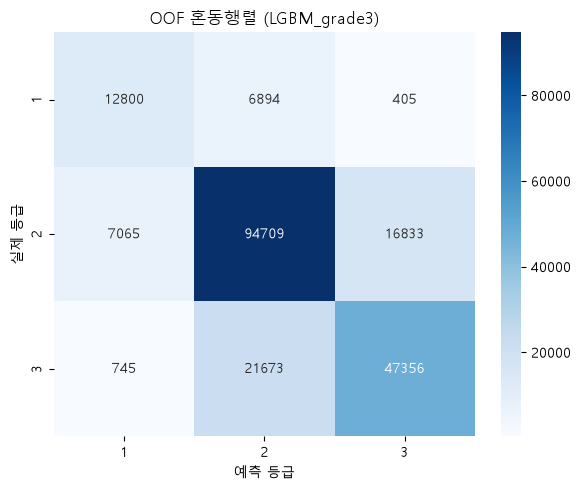

In [14]:
oof_rows = []

for name in ["LGBM_raw", winner_name]:
    oof_rows.append({"name": name, **metrics(y, oof[name])})

oof_table = pd.DataFrame(oof_rows)
save_table(oof_table, "oof_metrics")
display(oof_table.set_index("name").T.round(5))

print(
    classification_report(
        y,
        oof[winner_name],
        labels=LABELS,
        digits=4,
        zero_division=0
    )
)

report_dict = classification_report(
    y,
    oof[winner_name],
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

report_table = pd.DataFrame({
    name: report_dict[name]
    for name in ["1", "2", "3", "macro avg", "weighted avg"]
}).T

save_table(report_table.reset_index(names="grade"), "oof_classification_report")

cm = confusion_matrix(y, oof[winner_name], labels=LABELS)

cm_table = pd.DataFrame(cm, index=LABELS, columns=["pred1", "pred2", "pred3"])
save_table(cm_table.reset_index(names="actual"), "oof_confusion_matrix")

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS,
    ax=ax
)

ax.set_title(f"OOF 혼동행렬 ({winner_name})")
ax.set_xlabel("예측 등급")
ax.set_ylabel("실제 등급")

plt.tight_layout()
plt.savefig(OUT / "oof_confusion_matrix.png", dpi=160)
plt.show()

## 9. 일반화 진단: 처음 보는 지역과 중복 행

1. **처음 보는 geo_level_2**: development 안에서 geo_level_2_id 단위 GroupKFold(5)를 돌립니다. 학습 때 본 지역에서의 점수(5절)와 같이 보고해야 합니다.
2. **중복 입력**: 검증 fold 행 중 입력 38열이 학습 fold의 어떤 행과 완전히 같은 비율입니다. 무작위 분할에서 점수가 부풀 수 있는 정도를 보여 줍니다.

In [15]:
group_cv = GroupKFold(n_splits=5)
group_folds = list(group_cv.split(X, y, groups=X["geo_level_2_id"]))

group_rows = []

for config in [by_name["LGBM_raw"], winner]:
    for fold_number, (tr, va) in enumerate(group_folds):
        assert not set(X.iloc[tr]["geo_level_2_id"]) & set(X.iloc[va]["geo_level_2_id"])

        bundle = train_model(X.iloc[tr], y.iloc[tr], config)
        fold_pred = predict_model(bundle, X.iloc[va])

        group_rows.append({
            "name": config["name"],
            "fold": fold_number,
            "valid_n": len(va),
            **metrics(y.iloc[va], fold_pred)
        })

group_table = pd.DataFrame(group_rows)
save_table(group_table, "group_geo2_folds")

group_summary = (
    group_table.groupby("name")["macro_f1"]
    .agg(["mean", "std"])
    .reset_index()
)

save_table(group_summary, "group_geo2_summary")
display(group_summary.round(5))

# 중복 입력 비율
row_hash = pd.util.hash_pandas_object(X, index=False).to_numpy()

duplicate_rows = []

for fold_number, (tr, va) in enumerate(folds):
    duplicate_rows.append({
        "fold": fold_number,
        "valid_rows_with_identical_train_input": float(np.isin(row_hash[va], row_hash[tr]).mean())
    })

duplicate_table = pd.DataFrame(duplicate_rows)
save_table(duplicate_table, "cv_duplicate_input_ratio")
display(duplicate_table.round(4))

,name,mean,std
0,LGBM_grade3,0.57412,0.00905
1,LGBM_raw,0.54211,0.01190


,fold,valid_rows_with_identical_train_input
0,0,0.0806
1,1,0.0802
2,2,0.0796
3,3,0.0797
4,4,0.0793


## 10. 결과 요약

모든 숫자는 같은 development 데이터와 같은 fold에서 나왔습니다. 홀드아웃 점수는 없습니다.

In [16]:
stage1_lookup = cv_summary.set_index("name")
group_lookup = group_summary.set_index("name")

result_summary = pd.DataFrame({
    "항목": [
        "Dummy 5-fold CV Macro F1",
        "Logistic 5-fold CV Macro F1",
        "RandomForest 5-fold CV Macro F1 (geo 숫자 입력)",
        "LGBM_raw 5-fold CV Macro F1",
        f"후보 {winner_name} 5-fold CV Macro F1",
        "후보 - LGBM_raw (fold별 짝지은 차이 평균)",
        "LGBM_raw 처음 보는 geo2 Macro F1",
        f"후보 {winner_name} 처음 보는 geo2 Macro F1",
        "검증 행 중 학습 fold와 입력이 같은 비율"
    ],
    "값": [
        stage1_lookup.loc["Dummy", "mean"],
        stage1_lookup.loc["Logistic", "mean"],
        stage1_lookup.loc["RandomForest", "mean"],
        stage1_lookup.loc["LGBM_raw", "mean"],
        stage1_lookup.loc[winner_name, "mean"],
        pairwise.loc[0, "mean_diff"],
        group_lookup.loc["LGBM_raw", "mean"],
        group_lookup.loc[winner_name, "mean"],
        duplicate_table["valid_rows_with_identical_train_input"].mean()
    ]
})

display(result_summary.round({"값": 5}))
save_table(result_summary, "result_summary")

,항목,값
0,Dummy 5-fold CV Macro F1,0.24174
1,Logistic 5-fold CV Macro F1,0.66939
2,RandomForest 5-fold CV Macro F1 (geo 숫자 입력),0.61490
3,LGBM_raw 5-fold CV Macro F1,0.69860
4,후보 LGBM_grade3 5-fold CV Macro F1,0.70560
5,후보 - LGBM_raw (fold별 짝지은 차이 평균),0.00700
6,LGBM_raw 처음 보는 geo2 Macro F1,0.54211
7,후보 LGBM_grade3 처음 보는 geo2 Macro F1,0.57412
8,검증 행 중 학습 fold와 입력이 같은 비율,0.07988


## 11. 최종 홀드아웃 평가 계획 (실행하지 않음)

AGENTS.md에 따라 최종 후보와 평가 계획을 사용자/팀이 확정하기 전에는 홀드아웃을 열지 않습니다. 이 노트북은 후보와 계획만 저장합니다.

확정 후 할 일 (별도 노트북에서 1회만):
1. 아래 `selected_candidate_before_holdout.json`의 설정으로 development 전체(208,480행)를 학습합니다.
2. `data/final_holdout/`의 입력으로 예측한 뒤 정답과 비교합니다. Macro F1, 클래스별 P/R/F1, 혼동행렬을 남깁니다.
3. 결과를 보고 설정을 바꾸지 않습니다. 홀드아웃 점수는 5-fold CV 점수, 처음 보는 geo2 점수와 함께 보고합니다.

In [17]:
candidate = {
    "status": "candidate_pending_user_confirmation",
    "holdout_evaluated": False,
    "selected": winner,
    "selection_rule": "highest mean 5-fold macro F1 on frozen development folds",
    "cv_mean_macro_f1": float(stage1_lookup.loc[winner_name, "mean"]),
    "cv_std_macro_f1": float(stage1_lookup.loc[winner_name, "std"]),
    "diff_vs_lgbm_raw": float(pairwise.loc[0, "mean_diff"]),
    "unseen_geo2_macro_f1": float(group_lookup.loc[winner_name, "mean"]),
    "environment": environment
}

save_json(candidate, "selected_candidate_before_holdout.json")
print(json.dumps(candidate["selected"], ensure_ascii=False, indent=2))

{
  "name": "LGBM_grade3",
  "kind": "lgbm",
  "features": "raw",
  "method": "grade3"
}


## 12. 무결성 검사

In [18]:
saved_cv = pd.read_csv(OUT / "cv_folds.csv")

# 모든 후보가 같은 5개 fold로 평가됐는지
assert saved_cv.groupby("name")["fold"].apply(lambda s: sorted(s) == [0, 1, 2, 3, 4]).all()

# OOF 예측이 development 전체를 덮고, fold 점수 평균과 저장 요약이 일치하는지
for name, pred in oof.items():
    assert len(pred) == len(X) and set(np.unique(pred)) <= set(LABELS)

assert np.isclose(
    saved_cv.loc[saved_cv["name"] == winner_name, "macro_f1"].mean(),
    candidate["cv_mean_macro_f1"]
)

# 지역 표의 건수 합이 development 행 수와 같은지
for geo in GEO:
    table = pd.read_csv(OUT / f"dev_{geo}_all_grades.csv")

    assert table["n"].sum() == len(X)
    assert (table[["count_1", "count_2", "count_3"]].sum(axis=1) == table["n"]).all()
    assert np.allclose(table[["rate_1", "rate_2", "rate_3"]].sum(axis=1), 1)

# 홀드아웃 결과 파일이 만들어지지 않았는지
assert not list(OUT.glob("*holdout*.csv"))
assert candidate["holdout_evaluated"] is False

print("fold·OOF·집계·홀드아웃 미사용 검사를 통과했습니다.")

fold·OOF·집계·홀드아웃 미사용 검사를 통과했습니다.
